# Лабораторна робота 3. Агенти на основі знань

Мережевий контролер із ЛР2 доповнено базою знань про стан каналів (link-state database). Контролер виконує цикл KBA: отримати дані → TELL → ASK → виконати дію → перевірити мету.

In [1]:
import heapq
import math
import random
import statistics

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

## 1. Генератор топології (ЛР1)

In [2]:
def generate_graph_topology(num_nodes=25, edges_to_remove=5, weight_min=1, weight_max=10, seed=None):
    """Генератор топології з ЛР1; додано параметр seed для відтворюваності експериментів."""
    rng = random.Random(seed)
    G = nx.Graph()

    cols = math.ceil(math.sqrt(num_nodes))
    rows = math.ceil(num_nodes / cols)

    node_count = 0
    for r in range(rows):
        for c in range(cols):
            if node_count >= num_nodes:
                break
            G.add_node((r, c), address=f"10.0.{r}.{c}", pos=(c, -r))
            node_count += 1

    for r in range(rows):
        for c in range(cols):
            if not G.has_node((r, c)):
                continue
            if G.has_node((r, c + 1)):
                G.add_edge((r, c), (r, c + 1), weight=rng.randint(weight_min, weight_max))
            if G.has_node((r + 1, c)):
                G.add_edge((r, c), (r + 1, c), weight=rng.randint(weight_min, weight_max))

    removed_count, attempts = 0, 0
    while removed_count < edges_to_remove and attempts < 1000:
        edges = list(G.edges())
        if not edges:
            break
        u, v = rng.choice(edges)
        weight = G[u][v]['weight']
        G.remove_edge(u, v)
        if nx.is_connected(G):
            removed_count += 1
        else:
            G.add_edge(u, v, weight=weight)
        attempts += 1

    if removed_count < edges_to_remove:
        print(f"Увага: вдалося видалити лише {removed_count} ребер без втрати зв'язності.")
    return G

## 2. Контролер ЛР2 (для порівняння)

Площина даних і контролер з обмеженою видимістю з попередньої роботи залишено без змін.

In [3]:
# Інтерфейси вузла: північ, схід, південь, захід (зміщення рядка та стовпця в сітці)
DIRECTIONS = {'N': (-1, 0), 'E': (0, 1), 'S': (1, 0), 'W': (0, -1)}


class DataPlane:
    """Площина даних (середовище): вузли лише пересилають пакети за встановленими правилами.
    Усі рішення приймає контролер, а граф G доступний лише цьому класу."""

    def __init__(self, G, src_addr, dst_addr):
        self.G = G
        self._node = {d['address']: n for n, d in G.nodes(data=True)}
        for addr in (src_addr, dst_addr):
            if addr not in self._node:
                raise ValueError(f"Адреси {addr} немає в мережі")
        self.head = src_addr   # вузол, на якому закінчується встановлена частина шляху
        self.rules = []        # встановлені правила: (вузол, інтерфейс)

    def packet_in(self):
        """Подія «невідомий потік»: голова потоку надсилає контролеру свою таблицю каналів
        у вигляді {інтерфейс: (адреса сусіда, затримка каналу)}."""
        node = self._node[self.head]
        links = {}
        for d, (dr, dc) in DIRECTIONS.items():
            nb = (node[0] + dr, node[1] + dc)
            if self.G.has_edge(node, nb):
                links[d] = (self.G.nodes[nb]['address'], self.G[node][nb]['weight'])
        return self.head, links

    def install_rule(self, direction):
        """Дія 1: встановити правило через інтерфейс; голова переходить на сусіда."""
        head, links = self.packet_in()
        if direction not in links:
            raise ValueError(f"Вузол {head} не має каналу {direction}")
        self.rules.append((head, direction))
        self.head = links[direction][0]

    def revoke_last_rule(self):
        """Дія 2: відкликати останнє правило; голова повертається на попередній вузол."""
        node_addr, _ = self.rules.pop()
        self.head = node_addr

In [4]:
class SDNController:
    """Раціональний агент-контролер з обмеженою видимістю (оперативний пошук у глибину
    з жадібною евристикою та відкликанням правил у тупиках).

    alpha - вага евристичної оцінки відстані до отримувача відносно затримки каналу."""

    def __init__(self, src, dst, alpha=1.0):
        self.src, self.dst, self.alpha = src, dst, alpha
        self.dst_xy = self._xy(dst)   # координати отримувача з адреси 10.0.<рядок>.<стовпець>
        self.links = {}               # карта: {вузол_a, вузол_b} -> затримка (побачені канали)
        self.visited = set()          # вузли, з яких уже надходила телеметрія
        self.dead = set()             # вузли-тупики (правило до них відкликано)
        self.path = [src]             # вузли встановленого шляху
        self.rules = []               # встановлені правила (вузол, інтерфейс)
        self.installed = 0            # лічильники накладних витрат площини керування
        self.revoked = 0
        self.log, self.frames = [], []

    @staticmethod
    def _xy(addr):
        _, _, r, c = addr.split('.')
        return int(r), int(c)

    def _manhattan(self, addr):
        r, c = self._xy(addr)
        return abs(r - self.dst_xy[0]) + abs(c - self.dst_xy[1])

    def _perceive(self, head, links):
        """Оновлення карти за телеметрією голови потоку."""
        self.visited.add(head)
        for nb, w in links.values():
            self.links[frozenset((head, nb))] = w

    def _choose(self, links):
        """Серед ще не відвіданих сусідів обирає мінімум оцінки: затримка каналу +
        alpha * (середня відома затримка) * (манхеттенська відстань сусіда до отримувача)."""
        avg = sum(self.links.values()) / len(self.links)
        best = None
        for d, (nb, w) in links.items():
            if nb in self.visited:
                continue
            key = (w + self.alpha * avg * self._manhattan(nb), w)
            if best is None or key < best[0]:
                best = (key, d, nb, w)
        return best

    @property
    def delay(self):
        """Показник ефективності: сумарна затримка встановленого шляху."""
        return sum(self.links[frozenset(p)] for p in zip(self.path, self.path[1:]))

    def run(self, dp, verbose=False, max_steps=10_000):
        """Цикл: packet_in -> оновлення карти -> дія (встановити / відкликати / завершити)."""
        for step in range(1, max_steps + 1):
            head, links = dp.packet_in()
            self._perceive(head, links)
            done, ok = False, True

            if head == self.dst:
                text, short = "отримувача досягнуто, завершити шлях", "завершення"
                done = True
            else:
                choice = self._choose(links)
                if choice is not None:
                    _, d, nb, w = choice
                    dp.install_rule(d)
                    self.rules.append((head, d))
                    self.path.append(nb)
                    self.installed += 1
                    text = f"встановити правило {d}: {head} → {nb} (затримка {w})"
                    short = f"встановити {d}"
                elif self.rules:
                    self.dead.add(head)
                    prev, d = self.rules.pop()
                    self.path.pop()
                    dp.revoke_last_rule()
                    self.revoked += 1
                    text = f"тупик, відкликати правило {d} на вузлі {prev}"
                    short = "відкликати правило"
                else:
                    text, short = "відкликати нічого, шляху не існує", "невдача"
                    done, ok = True, False

            seen = ", ".join(f"{d}→{nb} ({w})" for d, (nb, w) in links.items())
            line = f"Крок {step:2d} | голова {head} | канали: {seen} | дія: {text}"
            self.log.append(line)
            if verbose:
                print(line)
            self.frames.append(dict(step=step, head=dp.head, path=list(self.path),
                                    known=set(self.links), dead=set(self.dead), short=short))
            if done:
                return ok
        return False

    def summary(self):
        return dict(nodes=len(self.path), delay=self.delay,
                    installed=self.installed, revoked=self.revoked)

## 3. Площина даних з анонсами станів каналів

При `packet_in` вузол передає не лише власні канали, а й анонси каналів сусідів (як OSPF), тому контролер знає структуру та затримки на два кроки вперед.

In [5]:
class DataPlaneLSA(DataPlane):
    """Площина даних ЛР3: окрім таблиці власних каналів, вузол передає анонси стану каналів
    сусідів (як OSPF). Працює з копією графа, щоб збій не змінював вихідну топологію."""

    def __init__(self, G, src_addr, dst_addr):
        super().__init__(G.copy(), src_addr, dst_addr)

    def _links_of(self, addr):
        node = self._node[addr]
        links = {}
        for d, (dr, dc) in DIRECTIONS.items():
            nb = (node[0] + dr, node[1] + dc)
            if self.G.has_edge(node, nb):
                links[d] = (self.G.nodes[nb]['address'], self.G[node][nb]['weight'])
        return links

    def packet_in(self):
        """Повертає голову, її канали та анонси каналів усіх сусідів голови."""
        head, links = super().packet_in()
        return head, links, {nb: self._links_of(nb) for nb, _ in links.values()}

    def install_rule(self, direction):
        head, links = super().packet_in()
        if direction not in links:
            raise ValueError(f"Вузол {head} не має каналу {direction}")
        self.rules.append((head, direction))
        self.head = links[direction][0]

    def degrade_link(self, a, b, factor):
        """Емуляція збою: затримка каналу a-b зростає в factor разів."""
        na, nb = self._node[a], self._node[b]
        self.G[na][nb]['weight'] *= factor

    def announce(self, addr):
        """Оновлений анонс вузла після зміни стану його каналів."""
        return self._links_of(addr)


## 4. База знань і контролер на основі знань

`LinkStateDB` зберігає вузли, канали та затримки. `TELL` записує анонси в базу. `ASK` виконує Дейкстру по відомій частині мережі: якщо отримувач уже відомий, будує до нього найкоротший відомий шлях, інакше обирає відомий невідвіданий вузол з мінімумом оцінки `g + α·avg·h + β·avg·(кількість правил для відкликання)`. Правила, що не входять до плану, відкликаються.

In [6]:
class LinkStateDB:
    """База знань контролера: база даних станів каналів (link-state database).
    Зберігає відомі вузли, канали з затримками та відповідність інтерфейсів."""

    def __init__(self):
        self.edges = {}      # frozenset({a, b}) -> затримка
        self.iface = {}      # (a, b) -> інтерфейс вузла a до сусіда b
        self.nodes = set()
        self.version = 0     # збільшується при кожній зміні затримки відомого каналу

    def tell(self, origin, links):
        """TELL: запис анонсу вузла origin {інтерфейс: (сусід, затримка)}.
        Повертає список каналів, затримка яких змінилась порівняно з базою."""
        changed = []
        self.nodes.add(origin)
        for d, (nb, w) in links.items():
            key = frozenset((origin, nb))
            if key in self.edges and self.edges[key] != w:
                changed.append(key)
                self.version += 1
            self.edges[key] = w
            self.iface[(origin, nb)] = d
            self.nodes.add(nb)
        return changed

    def neighbours(self, a):
        for key, w in self.edges.items():
            if a in key:
                (b,) = key - {a}
                yield b, w

    def shortest_paths(self, src):
        """Дейкстра по відомій частині мережі: відстані та попередники від src."""
        adj = {}
        for key, w in self.edges.items():
            a, b = tuple(key)
            adj.setdefault(a, []).append((b, w))
            adj.setdefault(b, []).append((a, w))
        dist, prev, heap = {src: 0}, {}, [(0, src)]
        while heap:
            d, u = heapq.heappop(heap)
            if d > dist[u]:
                continue
            for v, w in adj.get(u, []):
                if d + w < dist.get(v, math.inf):
                    dist[v], prev[v] = d + w, u
                    heapq.heappush(heap, (d + w, v))
        return dist, prev

    @staticmethod
    def restore(prev, src, node):
        path = [node]
        while path[-1] != src:
            path.append(prev[path[-1]])
        return path[::-1]


In [7]:
class KBAController:
    """Контролер-агент на основі знань: TELL оновлює базу, ASK обирає наступну дію.

    ASK: якщо отримувач уже є в базі - найкоротший відомий шлях до нього (Дейкстра по базі);
    інакше - шлях до відомого невідвіданого вузла з мінімумом g + alpha * avg * h, де g - відома
    вартість шляху від відправника, h - манхеттенська відстань до отримувача, avg - середня
    відома затримка. До оцінки додається штраф beta * avg за кожне правило, яке доведеться
    відкликати, щоб дійти до цілі (це зменшує «метання» між гілками). Правила, що не входять
    до плану, відкликаються."""

    def __init__(self, src, dst, alpha=1.0, beta=0.5):
        self.src, self.dst, self.alpha, self.beta = src, dst, alpha, beta
        self.dst_xy = self._xy(dst)
        self.kb = LinkStateDB()
        self.visited = set()
        self.path = [src]
        self.installed = self.revoked = 0
        self.log, self.frames = [], []

    @staticmethod
    def _xy(addr):
        _, _, r, c = addr.split('.')
        return int(r), int(c)

    def _h(self, addr):
        r, c = self._xy(addr)
        return abs(r - self.dst_xy[0]) + abs(c - self.dst_xy[1])

    def tell(self, head, links, lsas):
        """TELL: нові спостереження - власні канали голови та анонси її сусідів."""
        self.visited.add(head)
        self.kb.tell(head, links)
        for nb, nb_links in lsas.items():
            self.kb.tell(nb, nb_links)

    def ask(self):
        """ASK: цільовий шлях (список адрес від відправника) на основі бази знань."""
        dist, prev = self.kb.shortest_paths(self.src)
        if self.dst in dist:
            return self.kb.restore(prev, self.src, self.dst)
        avg = sum(self.kb.edges.values()) / len(self.kb.edges)
        frontier = [n for n in dist if n not in self.visited]
        if not frontier:
            return None
        def score(n):
            plan = self.kb.restore(prev, self.src, n)
            k = 0
            while k < len(self.path) and k < len(plan) and self.path[k] == plan[k]:
                k += 1
            revoke = len(self.path) - k   # скільки правил доведеться відкликати
            return (dist[n] + self.alpha * avg * self._h(n) + self.beta * avg * revoke, dist[n])
        target = min(frontier, key=score)
        return self.kb.restore(prev, self.src, target)

    @property
    def delay(self):
        return sum(self.kb.edges[frozenset(p)] for p in zip(self.path, self.path[1:]))

    def _note(self, step, head, text, phase):
        line = f"[{phase}] Крок {step:2d} | голова {head} | {text}"
        self.log.append(line)
        return line

    def _frame(self, step, dp, short):
        self.frames.append(dict(step=step, head=dp.head, path=list(self.path),
                                known=set(self.kb.edges), dead=self.visited - set(self.path),
                                short=short))

    def _revoke(self, dp):
        prev, _ = dp.rules[-1]
        dp.revoke_last_rule()
        self.path.pop()
        self.revoked += 1
        return prev

    def on_update(self, dp, origin, step):
        """Анонс про зміну каналів вузла origin: TELL, відкликання неактуальних правил, перебудова."""
        changed = self.kb.tell(origin, dp.announce(origin))
        bad = [i for i, p in enumerate(zip(self.path, self.path[1:])) if frozenset(p) in changed]
        lines = [self._note(step, dp.head, f"отримано оновлений анонс вузла {origin}; змінені канали: "
                            + (", ".join(f"{'-'.join(sorted(k))} (тепер {self.kb.edges[k]})" for k in changed)
                               or "немає (база вже містить нові значення)"), "збій")]
        if bad:
            while len(self.path) > bad[0] + 1:
                node = self._revoke(dp)
                lines.append(self._note(step, dp.head, f"відкликано правило на вузлі {node}: "
                                        "канал шляху змінився, правило неактуальне", "збій"))
        return lines

    def run(self, dp, verbose=False, max_steps=500, fault=None):
        """Цикл KBA: отримати дані -> TELL -> ASK -> виконати дію -> перевірити мету.
        fault = (кількість встановлених правил, індекс каналу шляху, множник) - необов'язковий збій."""
        step, fault_done, phase = 0, fault is None, "до збою"
        while step < max_steps:
            step += 1
            head, links, lsas = dp.packet_in()
            self.tell(head, links, lsas)
            out = []

            if not fault_done and self.installed >= fault[0]:
                i, factor = fault[1], fault[2]
                a, b = self.path[i], self.path[i + 1]
                dp.degrade_link(a, b, factor)
                out.append(self._note(step, head, f"збій: затримка каналу {a}-{b} зросла у {factor} разів", "збій"))
                out += self.on_update(dp, a, step)
                out += self.on_update(dp, b, step)
                fault_done, phase = True, "після збою"
                head, links, lsas = dp.packet_in()
                self.tell(head, links, lsas)

            if head == self.dst:
                out.append(self._note(step, head, "TELL виконано; отримувача досягнуто, завершення", phase))
                short, done = "завершення", True
            else:
                plan = self.ask()
                if plan is None:
                    out.append(self._note(step, head, "ASK: шляху не існує", phase))
                    short, done = "невдача", True
                else:
                    done, k = False, 0
                    while k < len(self.path) and k < len(plan) and self.path[k] == plan[k]:
                        k += 1
                    target = f"план до {plan[-1]} (довжина {len(plan) - 1})"
                    if len(self.path) > k:
                        node = self._revoke(dp)
                        out.append(self._note(step, head, f"ASK: {target}; відкликати правило на вузлі {node}", phase))
                        short = "відкликати правило"
                    else:
                        nxt = plan[k]
                        d = self.kb.iface[(head, nxt)]
                        dp.install_rule(d)
                        self.path.append(nxt)
                        self.installed += 1
                        w = self.kb.edges[frozenset((head, nxt))]
                        out.append(self._note(step, head, f"ASK: {target}; встановити правило {d}: {head} → {nxt} (затримка {w})", phase))
                        short = f"встановити {d}"
            if verbose:
                print("\n".join(out))
            self._frame(step, dp, short)
            if done:
                return head == self.dst
        return False

    def summary(self):
        return dict(nodes=len(self.path), delay=self.delay,
                    installed=self.installed, revoked=self.revoked)


## 5. Візуалізація

In [8]:
LEGEND = [
    Line2D([], [], marker='o', ls='', markerfacecolor='lightgreen', markeredgecolor='dimgray', markersize=12, label='відправник'),
    Line2D([], [], marker='o', ls='', markerfacecolor='gold', markeredgecolor='dimgray', markersize=12, label='отримувач'),
    Line2D([], [], marker='o', ls='', markerfacecolor='orange', markeredgecolor='dimgray', markersize=12, label='вузол із правилом'),
    Line2D([], [], marker='o', ls='', markerfacecolor='lightgray', markeredgecolor='dimgray', markersize=12, label='тупик (правило відкликано)'),
    Line2D([], [], marker='o', ls='', markerfacecolor='lightblue', markeredgecolor='dimgray', markersize=12, label='відомий, ще не відвіданий'),
    Line2D([], [], marker='o', ls='', markerfacecolor='white', markeredgecolor='dimgray', markersize=12, label='невідомий вузол'),
    Line2D([], [], marker='o', ls='', markerfacecolor='white', markeredgecolor='red', markeredgewidth=3, markersize=12, label='голова потоку'),
    Line2D([], [], color='red', lw=4, label='встановлений шлях'),
]


def draw_state(G, frame, src, dst, ax=None, short=False, title=None):
    """Малює стан мережі після дії контролера: що встановлено, що відомо контролеру, де голова потоку."""
    a2n = {d['address']: n for n, d in G.nodes(data=True)}
    pos = nx.get_node_attributes(G, 'pos')
    standalone = ax is None
    if standalone:
        _, ax = plt.subplots(figsize=(10, 8))

    path = [a2n[a] for a in frame['path']]
    path_edges = list(zip(path, path[1:]))
    known_edges = [tuple(a2n[a] for a in e) for e in frame['known']]
    known_nodes = {n for e in known_edges for n in e}
    dead = {a2n[a] for a in frame['dead']}
    head = a2n[frame['head']]

    fill, border, width = [], [], []
    for n in G.nodes:
        if n == a2n[dst]:
            fill.append('gold')
        elif n == a2n[src]:
            fill.append('lightgreen')
        elif n in path:
            fill.append('orange')
        elif n in dead:
            fill.append('lightgray')
        elif n in known_nodes:
            fill.append('lightblue')
        else:
            fill.append('white')
        border.append('red' if n == head else 'dimgray')
        width.append(3.5 if n == head else 1)

    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#dddddd', style='dashed', width=1)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=known_edges, edge_color='gray', width=1.5)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=path_edges, edge_color='red', width=4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=fill, edgecolors=border,
                           linewidths=width, node_size=1100 if short else 2600)
    labels = {n: (G.nodes[n]['address'].split('.', 2)[2] if short else G.nodes[n]['address'])
              for n in G.nodes}
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=8 if short else 9, font_weight='bold')
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={e: G[e[0]][e[1]]['weight'] for e in known_edges},
                                 font_color='darkred', font_size=8 if short else 10)
    ax.set_title(title or f"Крок {frame['step']}: {frame['short']}", fontsize=10 if short else 14)
    ax.axis('off')
    if standalone:
        ax.legend(handles=LEGEND, loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=4, frameon=False)
        plt.show()


def show_frames(G, frames, src, dst, max_frames=8, cols=4):
    """Стан мережі після послідовних дій контролера (рівномірна вибірка з max_frames кадрів)."""
    n = len(frames)
    idx = list(range(n)) if n <= max_frames else \
        sorted({round(i * (n - 1) / (max_frames - 1)) for i in range(max_frames)})
    rows = math.ceil(len(idx) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.6 * rows))
    axes = list(axes.flat) if hasattr(axes, 'flat') else [axes]
    for ax, i in zip(axes, idx):
        draw_state(G, frames[i], src, dst, ax=ax, short=True)
    for ax in axes[len(idx):]:
        ax.axis('off')
    fig.legend(handles=LEGEND, loc='lower center', ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()

## 6. Запуск контролера на основі знань

In [9]:
SRC_ADDR, DST_ADDR = "10.0.0.0", "10.0.4.4"
G = generate_graph_topology(num_nodes=25, edges_to_remove=8, weight_min=1, weight_max=10, seed=9)

dp = DataPlaneLSA(G, SRC_ADDR, DST_ADDR)
kba = KBAController(SRC_ADDR, DST_ADDR)
kba.run(dp, verbose=True)

res = kba.summary()
print()
print("Шлях:", " → ".join(kba.path))
print(f"Кількість вузлів у шляху: {res['nodes']}")
print(f"Сумарна затримка шляху: {res['delay']}")
print(f"Встановлено правил: {res['installed']}, відкликано: {res['revoked']} "
      f"(викликано правил: {res['installed'] + res['revoked']})")
print(f"Відомих каналів у базі знань: {len(kba.kb.edges)} з {G.number_of_edges()}")

[до збою] Крок  1 | голова 10.0.0.0 | ASK: план до 10.0.1.1 (довжина 2); встановити правило S: 10.0.0.0 → 10.0.1.0 (затримка 10)
[до збою] Крок  2 | голова 10.0.1.0 | ASK: план до 10.0.1.2 (довжина 3); встановити правило E: 10.0.1.0 → 10.0.1.1 (затримка 8)
[до збою] Крок  3 | голова 10.0.1.1 | ASK: план до 10.0.1.2 (довжина 3); встановити правило E: 10.0.1.1 → 10.0.1.2 (затримка 2)
[до збою] Крок  4 | голова 10.0.1.2 | ASK: план до 10.0.3.2 (довжина 5); відкликати правило на вузлі 10.0.1.1
[до збою] Крок  5 | голова 10.0.1.1 | ASK: план до 10.0.3.2 (довжина 5); встановити правило S: 10.0.1.1 → 10.0.2.1 (затримка 6)
[до збою] Крок  6 | голова 10.0.2.1 | ASK: план до 10.0.3.2 (довжина 5); встановити правило E: 10.0.2.1 → 10.0.2.2 (затримка 3)
[до збою] Крок  7 | голова 10.0.2.2 | ASK: план до 10.0.4.2 (довжина 6); встановити правило S: 10.0.2.2 → 10.0.3.2 (затримка 1)
[до збою] Крок  8 | голова 10.0.3.2 | ASK: план до 10.0.3.4 (довжина 7); встановити правило E: 10.0.3.2 → 10.0.3.3 (затри

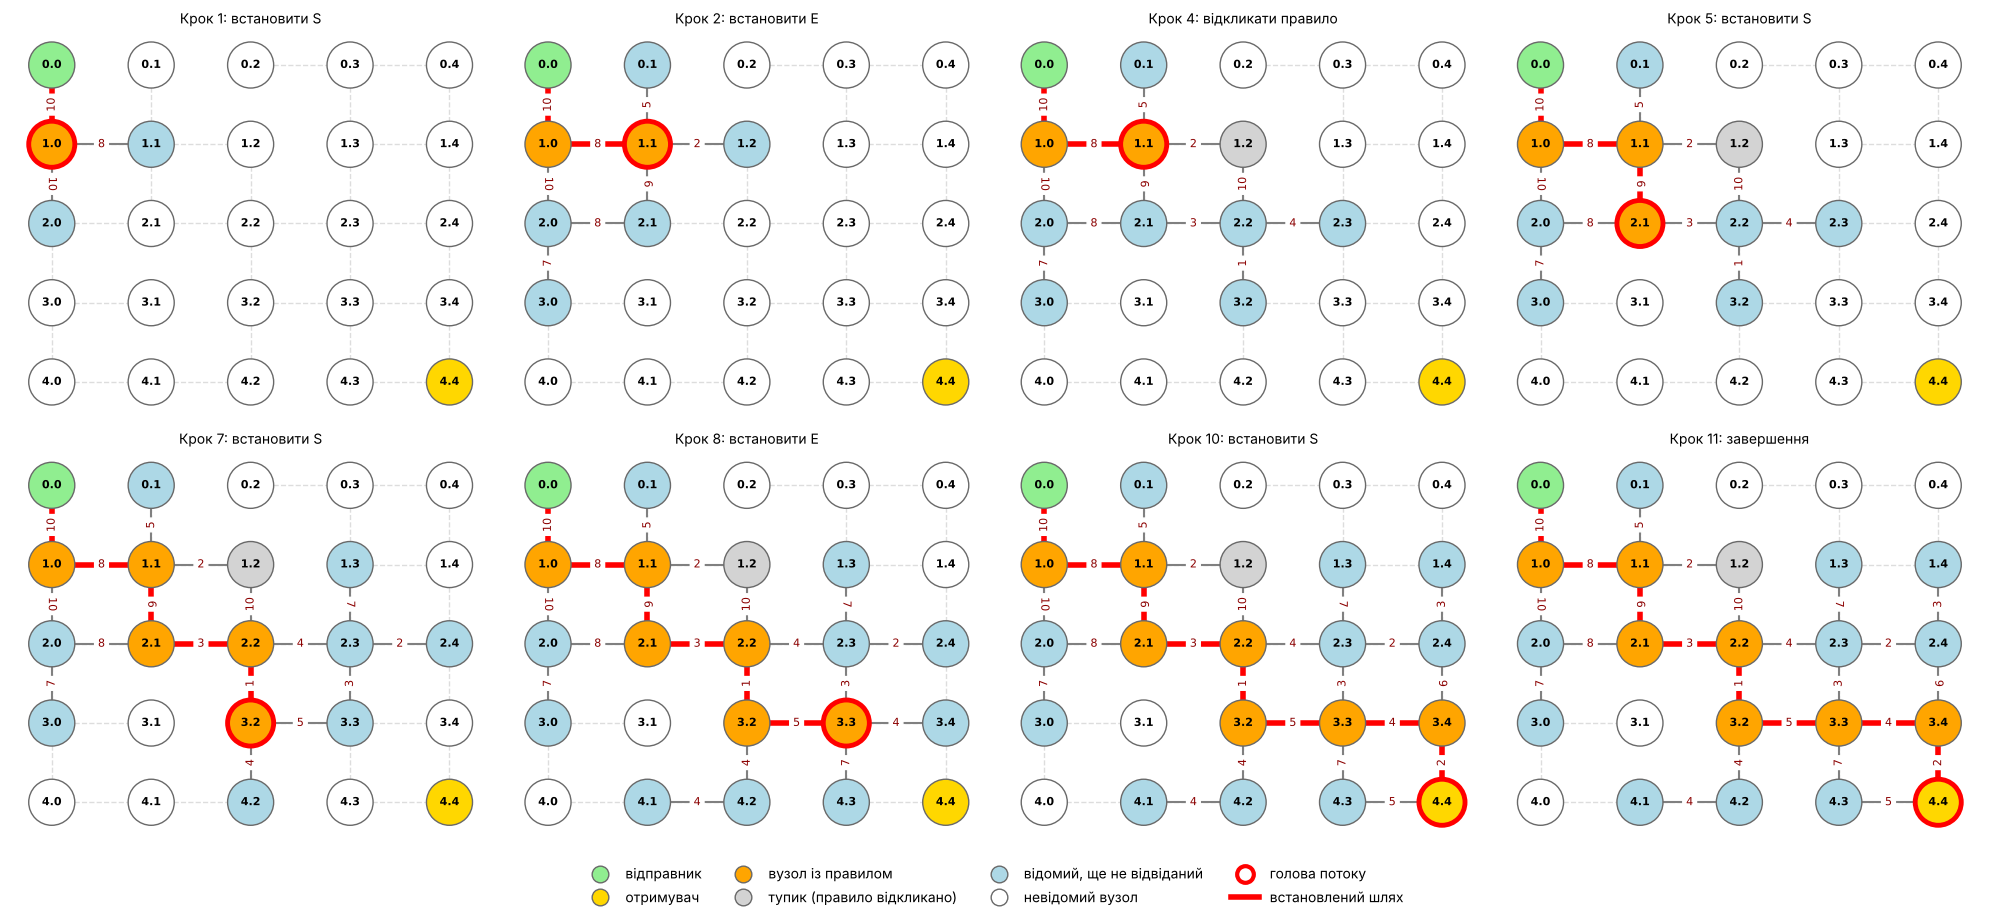

In [10]:
show_frames(G, kba.frames, SRC_ADDR, DST_ADDR, max_frames=8, cols=4)

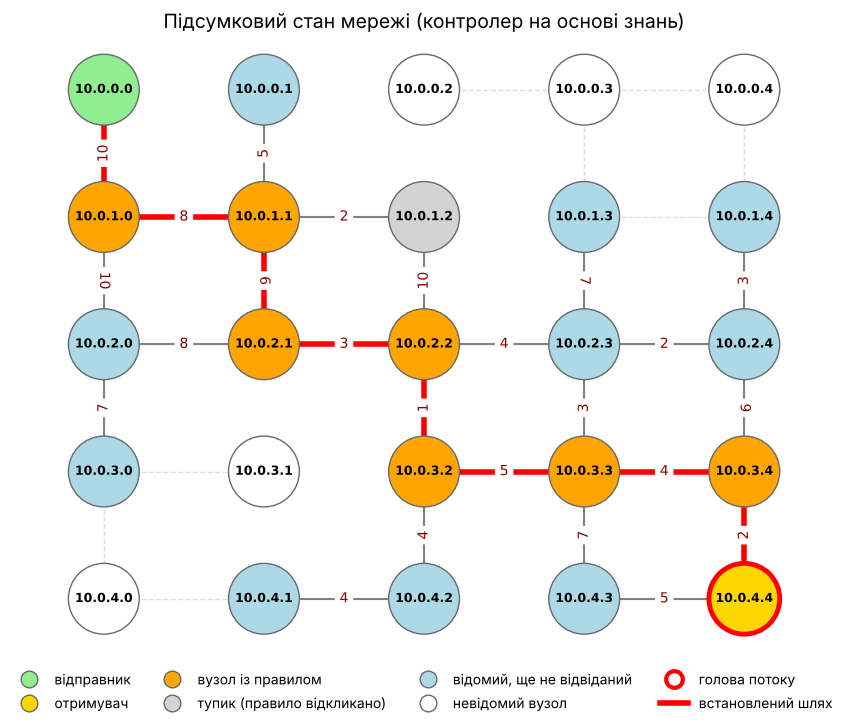

In [11]:
draw_state(G, kba.frames[-1], SRC_ADDR, DST_ADDR, title="Підсумковий стан мережі (контролер на основі знань)")

## 7. Додаткове завдання: порівняння з контролером ЛР2 та оптимальним шляхом (Дейкстра)

Для оптимального шляху кількість правил дорівнює кількості каналів шляху (вузли − 1).

In [12]:
def addr2node(G, addr):
    return next(n for n, d in G.nodes(data=True) if d['address'] == addr)


def compare(seeds, src, dst, num_nodes=25, edges_to_remove=8):
    """Порівняння: контролер ЛР3 (база знань), контролер ЛР2 (локальний пошук) та оптимум (Дейкстра)."""
    rows = []
    for seed in seeds:
        G = generate_graph_topology(num_nodes, edges_to_remove, 1, 10, seed=seed)
        old = SDNController(src, dst)
        old.run(DataPlane(G, src, dst))
        new = KBAController(src, dst)
        new.run(DataPlaneLSA(G, src, dst))
        a, b = addr2node(G, src), addr2node(G, dst)
        opt = nx.dijkstra_path(G, a, b, weight='weight')
        so, sn = old.summary(), new.summary()
        rows.append(dict(seed=seed, d2=so['delay'], d3=sn['delay'],
                         dopt=nx.dijkstra_path_length(G, a, b, weight='weight'),
                         n2=so['nodes'], n3=sn['nodes'], nopt=len(opt),
                         r2=so['installed'] + so['revoked'], r3=sn['installed'] + sn['revoked'],
                         ro=len(opt) - 1))
    return rows


def print_table(rows):
    head = (f"{'Топологія':>9} | {'Затримка ЛР2':>12} | {'Затримка ЛР3':>12} | {'Оптимум':>7} | "
            f"{'Вузлів ЛР2/ЛР3/опт.':>19} | {'Правил ЛР2':>10} | {'Правил ЛР3':>10} | {'Правил опт.':>11}")
    print(head)
    print("-" * len(head))
    for r in rows:
        print(f"{'seed=' + str(r['seed']):>9} | {r['d2']:>12} | {r['d3']:>12} | {r['dopt']:>7} | "
              f"{str(r['n2']) + ' / ' + str(r['n3']) + ' / ' + str(r['nopt']):>19} | "
              f"{r['r2']:>10} | {r['r3']:>10} | {r['ro']:>11}")
    avg = lambda k: sum(r[k] for r in rows) / len(rows)
    print("-" * len(head))
    print(f"{'середнє':>9} | {avg('d2'):>12.1f} | {avg('d3'):>12.1f} | {avg('dopt'):>7.1f} | "
          f"{avg('n2'):>5.1f} / {avg('n3'):>4.1f} / {avg('nopt'):>4.1f} | {avg('r2'):>10.1f} | "
          f"{avg('r3'):>10.1f} | {avg('ro'):>11.1f}")


rows = compare([1, 2, 3, 4, 5, 9], SRC_ADDR, DST_ADDR)
print_table(rows)

Топологія | Затримка ЛР2 | Затримка ЛР3 | Оптимум | Вузлів ЛР2/ЛР3/опт. | Правил ЛР2 | Правил ЛР3 | Правил опт.
---------------------------------------------------------------------------------------------------------------
   seed=1 |           47 |           38 |      38 |           9 / 9 / 9 |          8 |         20 |           8
   seed=2 |           34 |           34 |      24 |           9 / 9 / 9 |          8 |          8 |           8
   seed=3 |           40 |           40 |      40 |           9 / 9 / 9 |          8 |          8 |           8
   seed=4 |           56 |           38 |      38 |        13 / 11 / 11 |         12 |         12 |          10
   seed=5 |           40 |           40 |      40 |           9 / 9 / 9 |         16 |          8 |           8
   seed=9 |           42 |           39 |      39 |           9 / 9 / 9 |         22 |         10 |           8
--------------------------------------------------------------------------------------------------------

Те саме на 300 випадкових топологіях:

In [13]:
seeds = range(1000, 1300)   # 300 різних топологій
big = compare(seeds, SRC_ADDR, DST_ADDR)
mean = lambda k: statistics.mean(r[k] for r in big)
opt3 = sum(r['d3'] == r['dopt'] for r in big) / len(big)
opt2 = sum(r['d2'] == r['dopt'] for r in big) / len(big)
print(f"Середня затримка: ЛР2 {mean('d2'):.2f}, ЛР3 {mean('d3'):.2f}, оптимум {mean('dopt'):.2f}")
print(f"Середнє відношення до оптимуму: ЛР2 {statistics.mean(r['d2'] / r['dopt'] for r in big):.3f}, "
      f"ЛР3 {statistics.mean(r['d3'] / r['dopt'] for r in big):.3f}")
print(f"Частка оптимальних шляхів: ЛР2 {opt2:.0%}, ЛР3 {opt3:.0%}")
print(f"Середня кількість викликаних правил: ЛР2 {mean('r2'):.2f}, ЛР3 {mean('r3'):.2f}, оптимум {mean('ro'):.2f}")

Середня затримка: ЛР2 41.90, ЛР3 36.24, оптимум 35.85
Середнє відношення до оптимуму: ЛР2 1.178, ЛР3 1.012
Частка оптимальних шляхів: ЛР2 37%, ЛР3 93%
Середня кількість викликаних правил: ЛР2 11.13, ЛР3 11.90, оптимум 8.12


## 8. Завдання підвищеної складності: збій під час побудови шляху

Після встановлення 3 правил затримка другого каналу шляху зростає в 6 разів, вузол надсилає оновлений анонс. Контролер виконує TELL, відкликає неактуальні правила та перебудовує шлях.

In [14]:
G = generate_graph_topology(25, 8, 1, 10, seed=9)
dp = DataPlaneLSA(G, SRC_ADDR, DST_ADDR)
kba_f = KBAController(SRC_ADDR, DST_ADDR)
# після встановлення 3 правил затримка 2-го каналу шляху зростає у 6 разів
kba_f.run(dp, verbose=True, fault=(3, 1, 6))

print()
print("Шлях після збою:", " → ".join(kba_f.path))
s = kba_f.summary()
print(f"Затримка: {s['delay']}, вузлів: {s['nodes']}, встановлено правил: {s['installed']}, відкликано: {s['revoked']}")
G_deg = dp.G   # граф після збою
opt = nx.dijkstra_path_length(G_deg, addr2node(G, SRC_ADDR), addr2node(G, DST_ADDR), weight='weight')
print(f"Оптимальна затримка в мережі після збою (Дейкстра): {opt}")

[до збою] Крок  1 | голова 10.0.0.0 | ASK: план до 10.0.1.1 (довжина 2); встановити правило S: 10.0.0.0 → 10.0.1.0 (затримка 10)
[до збою] Крок  2 | голова 10.0.1.0 | ASK: план до 10.0.1.2 (довжина 3); встановити правило E: 10.0.1.0 → 10.0.1.1 (затримка 8)
[до збою] Крок  3 | голова 10.0.1.1 | ASK: план до 10.0.1.2 (довжина 3); встановити правило E: 10.0.1.1 → 10.0.1.2 (затримка 2)
[збій] Крок  4 | голова 10.0.1.2 | збій: затримка каналу 10.0.1.0-10.0.1.1 зросла у 6 разів
[збій] Крок  4 | голова 10.0.1.2 | отримано оновлений анонс вузла 10.0.1.0; змінені канали: 10.0.1.0-10.0.1.1 (тепер 48)
[збій] Крок  4 | голова 10.0.1.1 | відкликано правило на вузлі 10.0.1.1: канал шляху змінився, правило неактуальне
[збій] Крок  4 | голова 10.0.1.0 | відкликано правило на вузлі 10.0.1.0: канал шляху змінився, правило неактуальне
[збій] Крок  4 | голова 10.0.1.0 | отримано оновлений анонс вузла 10.0.1.1; змінені канали: немає (база вже містить нові значення)
[після збою] Крок  4 | голова 10.0.1.0 | 

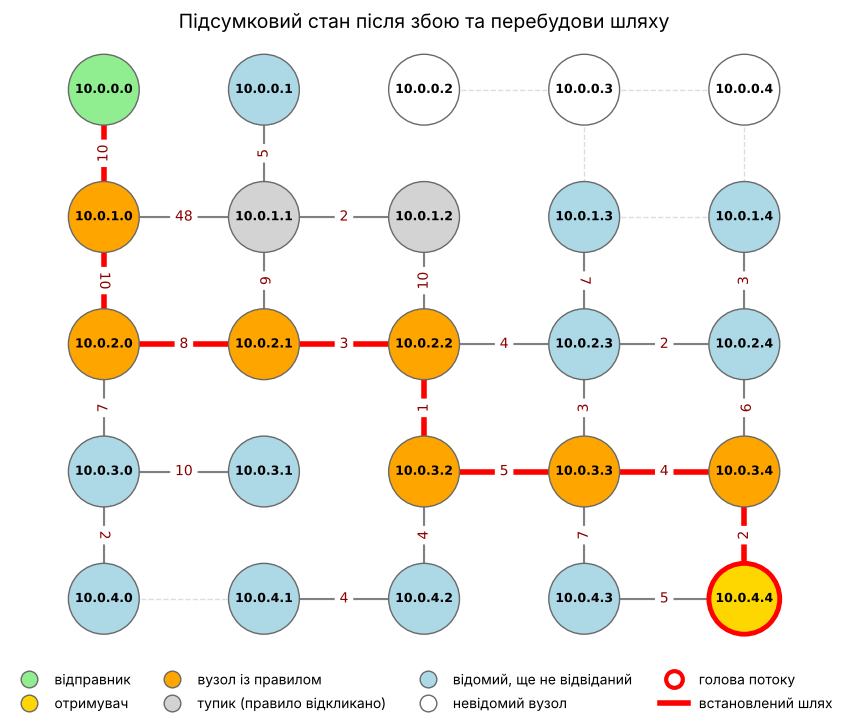

In [15]:
draw_state(dp.G, kba_f.frames[-1], SRC_ADDR, DST_ADDR, title="Підсумковий стан після збою та перебудови шляху")